# DSCI 552 Homework 7

Run all cells with Python 3.13 from a directory containing the course ZIP. Every run starts from the original CSV and writes fresh experiment results under `notebook_results/`.

## 1(a) Data and holdout

The 22 MFCC features are read from the ZIP. A seed-552 random row split makes one common test set. Syllables from the same recording may occur in both sets, so results apply to the assigned syllable-level holdout.

In [1]:
"""Reproduce the SVM and K-means experiments from the original course ZIP."""

import argparse
from hashlib import sha256
from io import BytesIO
import json
from pathlib import Path
from zipfile import ZipFile

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from joblib import Parallel, delayed, parallel_config
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from threadpoolctl import threadpool_limits

ARCHIVE = Path("Homework 7 Data.zip")
MEMBER = "Anuran Calls (MFCCs)/Frogs_MFCCs.csv"
RESULTS = Path("results")
FEATURES = [f"MFCCs_{i:2d}" for i in range(1, 23)]
TARGETS = ["Family", "Genus", "Species"]
MODEL_NAMES = ["RBF", "L1 linear", "L1 linear + SMOTE"]
SPLIT_SEED = 552
CV_SEED = 553
SMOTE_SEED = 554
SOLVER_SEED = 555
LINEAR_C = [0.001, 0.01, 0.1, 1, 10, 100]
RBF_C = [0.1, 1, 10, 100, 1000]
RBF_GAMMA = [0.0625, 0.25, 1, 4, 16, 64]
RUN_SEEDS = range(7001, 7051)
K_VALUES = range(2, 51)
N_INIT = 3


def read_member():
    with ZipFile(ARCHIVE) as archive:
        return archive.read(MEMBER)

RESULTS = Path("notebook_results")
RESULTS.mkdir(exist_ok=True)
data = read_member()
JOBS = 8

## 1(b)(i) Metrics

Exact match requires all three target slots to match. Mean Hamming distance counts wrong slots per row. Hamming loss divides that distance by three, and Hamming score is one minus loss.

The three slots are Family, Genus, and Species. Under [Sorower §7.1.1](https://www.researchgate.net/publication/266888594_A_Literature_Survey_on_Algorithms_for_Multi-label_Learning), the target-qualified 4 + 8 + 10 classes form 22 binary indicators. Each wrong slot creates one false positive and one false negative, so row $i$ has binary Hamming loss $2d_i/22$. The true and predicted label sets each have size three. Jaccard accuracy averages their per-row intersection-to-union ratios $(3-d_i)/(3+d_i)$. The metric review at the end computes both means directly from row-level labels.

In [2]:
def evaluate(truth, predictions):
    wrong = truth != predictions
    distance = wrong.sum(axis=1)
    return {
        "exact_match": float(np.mean(distance == 0)),
        "hamming_distance": float(distance.mean()),
        "hamming_score": float(np.mean(~wrong)),
        "hamming_loss": float(wrong.mean()),
        "wrong_slots": int(wrong.sum()),
        "exact_rows": int(np.sum(distance == 0)),
    }

## 1(b)(ii)–(iv) Gaussian, L1 linear, and L1 linear with SMOTE

Each target uses one-vs-rest with 10-fold stratified tuning by accuracy. The RBF kernel uses $\gamma=1/(2\sigma^2)$. Standardization and SMOTE are fitted inside the corresponding training folds.

In [3]:
def model_spec(name):
    if name == "RBF":
        estimator = OneVsRestClassifier(SVC(kernel="rbf", cache_size=256))
        grid = {"svm__estimator__C": RBF_C, "svm__estimator__gamma": RBF_GAMMA}
        return Pipeline([("svm", estimator)]), grid
    steps = [("scale", StandardScaler())]
    if name == "L1 linear + SMOTE":
        steps.append(("smote", SMOTE(k_neighbors=5, random_state=SMOTE_SEED)))
    steps.append(("svm", LinearSVC(penalty="l1", loss="squared_hinge", dual=False,
                                    multi_class="ovr", random_state=SOLVER_SEED,
                                    max_iter=100_000, tol=1e-4)))
    return Pipeline(steps), {"svm__C": LINEAR_C}


def run_svm(data, jobs):
    frame = pd.read_csv(BytesIO(data))
    assert frame.columns.tolist() == FEATURES + TARGETS + ["RecordID"]
    assert not frame.isna().any().any()
    features = frame[FEATURES].to_numpy()
    train, test = train_test_split(np.arange(len(frame)), test_size=0.30,
                                   random_state=SPLIT_SEED, shuffle=True)
    assert not np.intersect1d(train, test).size and len(train) + len(test) == len(frame)
    x_train, x_test = features[train], features[test]
    truth = frame.iloc[test][TARGETS].to_numpy()
    train_records = set(frame.iloc[train]["RecordID"])
    test_records = set(frame.iloc[test]["RecordID"])
    shared_records = train_records & test_records
    summary = {
        "csv_sha256": sha256(data).hexdigest(),
        "n_total": len(frame),
        "n_train": len(train),
        "n_test": len(test),
        "n_records": int(frame["RecordID"].nunique()),
        "n_train_records": len(train_records),
        "n_test_records": len(test_records),
        "n_shared_records": len(shared_records),
        "n_test_rows_shared_records": int(frame.iloc[test]["RecordID"].isin(shared_records).sum()),
        "split_seed": SPLIT_SEED,
        "cv_seed": CV_SEED,
        "smote_seed": SMOTE_SEED,
        "solver_seed": SOLVER_SEED,
        "models": {},
    }
    audit = frame.iloc[test][["RecordID", *TARGETS]].reset_index(drop=True)
    audit.insert(0, "row_index", test)
    cv_tables = []
    for name in MODEL_NAMES:
        choices = {}
        predictions = []
        for target_index, target in enumerate(TARGETS):
            y_train = frame.iloc[train][target].to_numpy()
            model, grid = model_spec(name)
            cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=CV_SEED)
            search = GridSearchCV(model, grid, scoring="accuracy", cv=cv,
                                  n_jobs=jobs, error_score="raise")
            search.fit(x_train, y_train)
            prediction = search.predict(x_test)
            predictions.append(prediction)
            audit[f"{name} | {target}"] = prediction
            classes = np.unique(y_train)
            assert set(truth[:, target_index]) == set(classes)
            per_class = {}
            for label in classes:
                actual = truth[:, target_index] == label
                true_positives = int(np.sum(actual & (prediction == label)))
                per_class[label] = {
                    "train_support": int(np.sum(y_train == label)),
                    "test_support": int(actual.sum()),
                    "true_positives": true_positives,
                    "recall": true_positives / int(actual.sum()),
                }
            choices[target] = {
                "C": float(next(value for key, value in search.best_params_.items()
                                if key.endswith("__C"))),
                "gamma": search.best_params_.get("svm__estimator__gamma"),
                "cv_accuracy": float(search.best_score_),
                "test_accuracy": float(np.mean(prediction == truth[:, target_index])),
                "macro_recall": float(np.mean([row["recall"] for row in per_class.values()])),
                "classes": per_class,
            }
            cv_table = pd.DataFrame(search.cv_results_)
            cv_table.insert(0, "model", name)
            cv_table.insert(1, "target", target)
            cv_tables.append(cv_table)
            print(name, target, search.best_params_, f"CV {search.best_score_:.5f}", flush=True)
        summary["models"][name] = {
            **evaluate(truth, np.column_stack(predictions)), "targets": choices
        }

    audit.to_csv(RESULTS / "svm_test_predictions.csv", index=False)
    pd.concat(cv_tables, ignore_index=True).to_csv(RESULTS / "svm_cv.csv", index=False)
    (RESULTS / "svm_summary.json").write_text(json.dumps(summary, indent=2) + "\n")

In [4]:
with threadpool_limits(limits=1), parallel_config(backend="loky", inner_max_num_threads=1):
    run_svm(data, JOBS)

svm = json.loads((RESULTS / "svm_summary.json").read_text())
print(f"Holdout: {svm['n_train']} train / {svm['n_test']} test; "
      f"{svm['n_shared_records']} shared recording IDs, {svm['n_test_rows_shared_records']} shared-record test rows")
fields = ["exact_match", "hamming_distance", "hamming_score", "hamming_loss"]
display(pd.DataFrame({
    name: {**{field: result[field] for field in fields},
           **{t: result["targets"][t]["test_accuracy"] for t in TARGETS}}
    for name, result in svm["models"].items()
}).T.round(6))
display(pd.DataFrame([
    {"model": name, "target": target, **{key: stats[key] for key in
     ("C", "gamma", "cv_accuracy", "macro_recall")}}
    for name, result in svm["models"].items() for target, stats in result["targets"].items()
]).round(6))
display(pd.DataFrame([
    {"model": name, "target": target, "class": label, **row}
    for name, result in svm["models"].items() for target, stats in result["targets"].items()
    for label, row in stats["classes"].items() if row["train_support"] < 200
]))

RBF Family {'svm__estimator__C': 10, 'svm__estimator__gamma': 4} CV 0.99325


RBF Genus {'svm__estimator__C': 10, 'svm__estimator__gamma': 4} CV 0.99186


RBF Species {'svm__estimator__C': 10, 'svm__estimator__gamma': 4} CV 0.99047


L1 linear Family {'svm__C': 1} CV 0.93765


L1 linear Genus {'svm__C': 100} CV 0.95393


L1 linear Species {'svm__C': 10} CV 0.95830


... (3 outputs left out)

Holdout: 5036 train / 2159 test; 57 shared recording IDs, 2157 shared-record test rows


,exact_match,hamming_distance,hamming_score,hamming_loss,Family,Genus,Species
RBF,0.986105,0.033349,0.988884,0.011116,0.991663,0.987494,0.987494
L1 linear,0.917091,0.157943,0.947352,0.052648,0.933302,0.952293,0.956461
L1 linear + SMOTE,0.864289,0.221862,0.926046,0.073954,0.916628,0.911070,0.950440


,model,target,C,gamma,cv_accuracy,macro_recall
0,RBF,Family,10.0,4.0,0.993249,0.971207
1,RBF,Genus,10.0,4.0,0.991857,0.957270
2,RBF,Species,10.0,4.0,0.990468,0.967121
3,L1 linear,Family,1.0,NaN,0.937649,0.692772
4,L1 linear,Genus,100.0,NaN,0.953930,0.831414
5,L1 linear,Species,10.0,NaN,0.958299,0.891290
6,L1 linear + SMOTE,Family,100.0,NaN,0.922359,0.933326
7,L1 linear + SMOTE,Genus,1.0,NaN,0.919577,0.886694
8,L1 linear + SMOTE,Species,10.0,NaN,0.957903,0.898481


,model,target,class,train_support,test_support,true_positives,recall
0,RBF,Family,Bufonidae,48,20,18,0.900000
1,RBF,Genus,Leptodactylus,186,84,81,0.964286
2,RBF,Genus,Osteocephalus,87,27,24,0.888889
3,RBF,Genus,Rhinella,48,20,18,0.900000
4,RBF,Genus,Scinax,101,47,45,0.957447
5,RBF,Species,LeptodactylusFuscus,186,84,82,0.976190
6,RBF,Species,OsteocephalusOophagus,87,27,25,0.925926
7,RBF,Species,Rhinellagranulosa,48,20,18,0.900000
8,RBF,Species,ScinaxRuber,101,47,45,0.957447
9,L1 linear,Family,Bufonidae,48,20,0,0.000000


## 2(a)–(c) K-means, cluster modes, and Monte Carlo results

Each seed independently maximizes CH over the 49 defined candidates. CH is undefined for $k=1$. True labels are loaded after partition selection. Each cluster receives three separately computed modes, with lexical tie-breaking.

In [5]:
def select_partition(features, seed):
    best_ch = -np.inf
    best_labels = None
    best_k = None
    scores = []
    for k in K_VALUES:
        fitted = KMeans(n_clusters=k, random_state=seed, n_init=N_INIT, init="k-means++",
                        algorithm="lloyd", max_iter=300, tol=1e-4).fit(features)
        labels = fitted.labels_
        assert np.unique(labels).size == k
        score = calinski_harabasz_score(features, labels)
        scores.append(score)
        if score > best_ch:
            best_ch, best_labels, best_k = score, labels, k
    print(f"K-means seed {seed}: k={best_k}, CH={best_ch:.3f}", flush=True)
    return best_k, best_ch, best_labels, scores


def assign_modes(truth, clusters, k):
    predictions = np.empty_like(truth)
    for cluster in range(k):
        members = clusters == cluster
        for column in range(len(TARGETS)):
            values, counts = np.unique(truth[members, column], return_counts=True)
            predictions[members, column] = values[counts.argmax()]
    return predictions


def run_kmeans(data, jobs):
    features = pd.read_csv(BytesIO(data), usecols=FEATURES)[FEATURES].to_numpy()
    assert np.isfinite(features).all()
    partitions = Parallel(n_jobs=jobs)(
        delayed(select_partition)(features, seed) for seed in RUN_SEEDS
    )
    # The labels are loaded only after every feature-only partition has been selected.
    truth = pd.read_csv(BytesIO(data), usecols=TARGETS)[TARGETS].to_numpy()
    runs, candidates = [], []
    cluster_columns = {}
    for run, (seed, partition) in enumerate(zip(RUN_SEEDS, partitions, strict=True), 1):
        k, score, clusters, scores = partition
        predictions = assign_modes(truth, clusters, k)
        metrics = evaluate(truth, predictions)
        runs.append({"run": run, "seed": seed, "k": k, "ch_score": score, **metrics})
        candidates.extend({"run": run, "seed": seed, "k": candidate, "ch_score": ch}
                          for candidate, ch in zip(K_VALUES, scores, strict=True))
        cluster_columns[f"seed_{seed}"] = clusters

    assert len(runs) == 50 and len(candidates) == 2450
    pd.DataFrame(runs).to_csv(RESULTS / "kmeans_monte_carlo.csv", index=False)
    pd.DataFrame(candidates).to_csv(RESULTS / "kmeans_ch_candidates.csv", index=False)
    np.savez_compressed(RESULTS / "kmeans_partitions.npz", **cluster_columns)

In [6]:
with threadpool_limits(limits=1), parallel_config(backend="loky", inner_max_num_threads=1):
    run_kmeans(data, JOBS)

runs = pd.read_csv(RESULTS / "kmeans_monte_carlo.csv")
assert len(runs) == runs.seed.nunique() == 50
display(runs.k.value_counts().sort_index().rename("runs"))
display(runs[fields[1:]].agg(["mean", "std", "min", "max"]).round(6))

K-means seed 7006: k=2, CH=3680.741


K-means seed 7002: k=2, CH=3680.741


K-means seed 7005: k=2, CH=3680.741
K-means seed 7003: k=2, CH=3680.741
K-means seed 7007: k=2, CH=3680.741
K-means seed 7001: k=2, CH=3680.741
K-means seed 7008: k=2, CH=3680.741


K-means seed 7004: k=2, CH=3680.741


K-means seed 7009: k=2, CH=3680.741


K-means seed 7013: k=2, CH=3680.741
K-means seed 7010: k=2, CH=3680.741
K-means seed 7014: k=2, CH=3680.741


... (19 outputs left out)

K-means seed 7048: k=2, CH=3680.741


K-means seed 7049: k=2, CH=3680.741
K-means seed 7050: k=2, CH=3680.741


k
2    50
Name: runs, dtype: int64

,hamming_distance,hamming_score,hamming_loss
mean,0.895622,0.701459,0.298541
std,0.000000,0.000000,0.000000
min,0.895622,0.701459,0.298541
max,0.895622,0.701459,0.298541


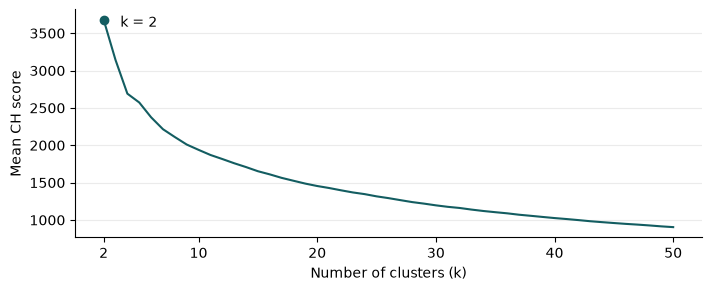

In [7]:
import matplotlib.pyplot as plt
candidates = pd.read_csv(RESULTS / "kmeans_ch_candidates.csv")
mean_ch = candidates.groupby("k").ch_score.mean()
fig, ax = plt.subplots(figsize=(7, 2.8), layout="constrained")
ax.plot(mean_ch.index, mean_ch, color="#135D61")
ax.scatter(2, mean_ch.loc[2], color="#135D61", zorder=3)
ax.annotate("k = 2", (2, mean_ch.loc[2]), xytext=(12, -5), textcoords="offset points")
ax.set(xlabel="Number of clusters (k)", ylabel="Mean CH score", xticks=[2, 10, 20, 30, 40, 50])
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

The line averages the CH score at each candidate $k$ over the 50 seeds. Each run selects its own maximum before this aggregation.

## 3. ISLR 12.6.2

[Second edition of ISL with R](https://www.statlearning.com/), §12.6, p. 546.

- **(a)** Complete linkage first merges 1 and 2 at 0.30. The resulting cluster has maximum cross-pair distances 0.50 and 0.80 to 3 and 4. Thus 3 and 4 merge at 0.45. The maximum cross-pair distance between the two clusters is 0.80.
- **(b)** Single linkage first merges 1 and 2 at 0.30. The minimum distances to 3 and 4 are 0.40 and 0.70. Merge 3 at 0.40, then 4 at the minimum cross-pair distance 0.45.
- **(c)** A complete-linkage cut at 0.60 yields {1, 2} and {3, 4}.
- **(d)** A single-linkage cut at 0.425 yields {1, 2, 3} and {4}.
- **(e)** Swap the root's children in (a) for leaf order 3, 4, 1, 2 with identical merge heights.

Extra Practice items 1(b)(v), 1(b)(vi), and 4 are omitted.

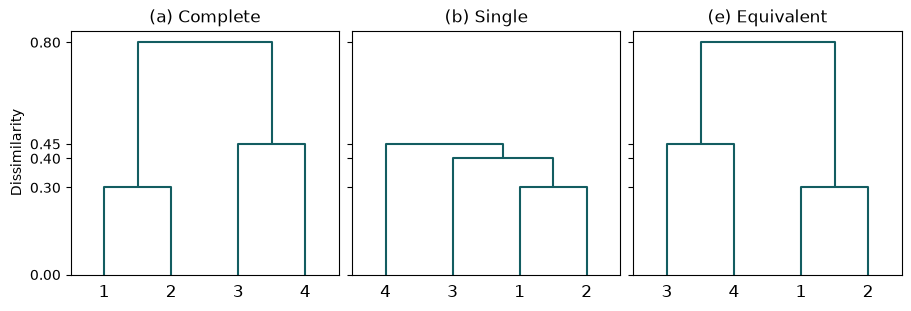

In [8]:
from scipy.cluster.hierarchy import dendrogram, linkage
distances = [0.30, 0.40, 0.70, 0.50, 0.80, 0.45]
complete = linkage(distances, method="complete")
single = linkage(distances, method="single")
equivalent = complete.copy()
equivalent[-1, :2] = complete[-1, :2][::-1]
fig, axes = plt.subplots(1, 3, figsize=(9, 3), sharey=True, layout="constrained")
for ax, tree, title in zip(axes, [complete, single, equivalent],
                           ["(a) Complete", "(b) Single", "(e) Equivalent"]):
    dendrogram(tree, labels=["1", "2", "3", "4"], ax=ax, color_threshold=0,
               above_threshold_color="#135D61")
    ax.set(title=title, yticks=[0, .30, .40, .45, .80])
axes[0].set_ylabel("Dissimilarity")
plt.show()

### Reproduction check

This full run started in a clean directory with the course ZIP. The saved report and original results match the rerun for all reported metrics, selected hyperparameters, test predictions, fold scores, CH candidate scores, and winning partitions. CV timing is runtime-dependent.

## Q1 and Q2 metric review from saved predictions

Run All to reproduce the fits from the course ZIP and use the newly generated files in \`notebook_results/\`. For an archive-only review, run the setup cell, the two function-definition cells for metrics and clustering, then these review cells. Without newly generated predictions in this kernel, the review reads \`results/\`. The outputs below were executed from the existing archive.

In [9]:
from IPython.display import display

def indicator_metrics(truth, predictions):
    """Average the Sorower metrics for three target-qualified labels per row."""
    distance = (truth != predictions).sum(axis=1)
    return {
        "binary_hamming_loss": float(np.mean(2 * distance / 22)),
        "jaccard_accuracy": float(np.mean((3 - distance) / (3 + distance))),
    }

review_dir = RESULTS if "svm" in globals() and "runs" in globals() else Path("results")
archive_frame = pd.read_csv(BytesIO(read_member()))
assert archive_frame[TARGETS].nunique().tolist() == [4, 8, 10]
new_fields = ["binary_hamming_loss", "jaccard_accuracy"]
print(f"Metric review source: {review_dir}")

Metric review source: results


In [10]:
test_predictions = pd.read_csv(review_dir / "svm_test_predictions.csv")
_, test_rows = train_test_split(np.arange(len(archive_frame)), test_size=0.30,
                                random_state=SPLIT_SEED, shuffle=True)
assert len(test_predictions) == len(test_rows) == 2159
np.testing.assert_array_equal(test_predictions.row_index, test_rows)
test_truth = archive_frame.iloc[test_rows][TARGETS].to_numpy()
np.testing.assert_array_equal(test_predictions[TARGETS].to_numpy(), test_truth)

model_rows = []
for name in MODEL_NAMES:
    prediction = test_predictions[[f"{name} | {target}" for target in TARGETS]].to_numpy()
    model_rows.append({
        "model": name, **evaluate(test_truth, prediction),
        **dict(zip(TARGETS, (test_truth == prediction).mean(axis=0))),
        **indicator_metrics(test_truth, prediction),
    })
model_review = pd.DataFrame(model_rows).set_index("model")
display(model_review.drop(columns=["wrong_slots", "exact_rows"]).round(6))

,exact_match,hamming_distance,hamming_score,hamming_loss,Family,Genus,Species,binary_hamming_loss,jaccard_accuracy
model,,,,,,,,,
RBF,0.986105,0.033349,0.988884,0.011116,0.991663,0.987494,0.987494,0.003032,0.987911
L1 linear,0.917091,0.157943,0.947352,0.052648,0.933302,0.952293,0.956461,0.014358,0.938907
L1 linear + SMOTE,0.864289,0.221862,0.926046,0.073954,0.916628,0.911070,0.950440,0.020169,0.908708


In [11]:
cluster_truth = archive_frame[TARGETS].to_numpy()
saved_runs = pd.read_csv(review_dir / "kmeans_monte_carlo.csv")
assert saved_runs.seed.tolist() == list(RUN_SEEDS)
run_metrics = []
with np.load(review_dir / "kmeans_partitions.npz") as partitions:
    for run in saved_runs.itertuples(index=False):
        clusters = partitions[f"seed_{run.seed}"]
        prediction = assign_modes(cluster_truth, clusters, run.k)
        run_metrics.append({
            **evaluate(cluster_truth, prediction),
            **indicator_metrics(cluster_truth, prediction),
        })
cluster_review = pd.DataFrame(run_metrics, index=saved_runs.seed)
old_fields = ["hamming_distance", "hamming_score", "hamming_loss"]
np.testing.assert_allclose(cluster_review[old_fields], saved_runs[old_fields])
display(cluster_review[old_fields + new_fields].agg(["mean", "std"]).round(6))
print(f"Reconstructed and scored {len(cluster_review)} saved partitions.")

,hamming_distance,hamming_score,hamming_loss,binary_hamming_loss,jaccard_accuracy
mean,0.895622,0.701459,0.298541,0.08142,0.68189
std,0.000000,0.000000,0.000000,0.00000,0.00000


Reconstructed and scored 50 saved partitions.
